<a href="https://colab.research.google.com/github/MegaDeadCowboy/jasper-burn-severity/blob/main/notebooks/06_rf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
![ -d /content/jasper-burn-severity ] || git clone https://github.com/MegaDeadCowboy/jasper-burn-severity.git /content/jasper-burn-severity
%cd /content/jasper-burn-severity
!pip install -q rioxarray geopandas

Cloning into '/content/jasper-burn-severity'...
remote: Enumerating objects: 272, done.
remote: Counting objects: 100% (86/86), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 272 (delta 46), reused 12 (delta 12), pack-reused 186 (from 1)
Receiving objects: 100% (272/272), 41.08 MiB | 16.63 MiB/s, done.
Resolving deltas: 100% (131/131), done.
/content/jasper-burn-severity
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.7 MB/s eta 0:00:00


In [2]:
import sys; sys.path.insert(0, ".")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, rioxarray
from rasterio.features import rasterize
from src.indices import ndvi, nbr
from google.colab import drive; drive.mount("/content/drive")

DATA = Path("/content/drive/MyDrive/jasper-burn-severity/data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
UTM, PIX_HA, BUFFER_M = 32611, 0.04, 2000
BURN_T, VEG_T = 0.10, 0.10
BANDS = ["B04", "B08", "B8A", "B12"]
BLOCK_PX = 100                                   # 2 km CV blocks

load = lambda f: rioxarray.open_rasterio(DATA / f, masked=True).assign_coords(band=BANDS).to_dataset("band")
pre, post = load("s2_pre_2023.tif"), load("s2_post_2025.tif")
d = rioxarray.open_rasterio(DATA / "dnbr_2023_2025.tif", masked=True).squeeze("band", drop=True)
perim = gpd.read_file(DATA / "nbac_jasper_2024.gpkg").to_crs(UTM)
town = gpd.read_file(DATA / "townsite_pc2021.gpkg").to_crs(UTM)
shape, transform = d.shape, d.rio.transform()

Mounted at /content/drive


In [3]:
## 1. Features, labels, evaluation mask (same as 03; other NBAC fires excluded 0 px there)
def burn(geoms):
    return rasterize(((g, 1) for g in geoms), out_shape=shape, transform=transform, fill=0, dtype="uint8").astype(bool)

ref = burn(perim.geometry)
in_aoi, in_town = burn(perim.buffer(BUFFER_M)), burn(town.geometry)

f = {f"{b}_pre": pre[b] for b in BANDS} | {f"{b}_post": post[b] for b in BANDS}
f |= {"ndvi_pre": ndvi(pre), "ndvi_post": ndvi(post), "nbr_pre": nbr(pre), "nbr_post": nbr(post)}
f["dnbr"], f["dndvi"] = f["nbr_pre"] - f["nbr_post"], f["ndvi_pre"] - f["ndvi_post"]
NAMES = list(f)
print("max |dNBR - file|:", float(np.nanmax(np.abs(f["dnbr"].values - d.values))))

m = in_aoi & ~in_town & np.isfinite(d.values) & (f["ndvi_pre"].values >= VEG_T)
idx = np.flatnonzero(m)
X = np.column_stack([f[k].values.ravel()[idx] for k in NAMES]).astype("float32")
y = ref.ravel()[idx]
ok = np.isfinite(X).all(1)
print(f"eval pixels {idx.size:,} (03: 1,388,035) | non-finite feature rows {(~ok).sum():,} | burned {y.mean():.1%}")

r, c = np.unravel_index(idx, shape)
blocks = (r // BLOCK_PX) * 10_000 + c // BLOCK_PX
print(f"{np.unique(blocks).size} blocks of 2 km")

def scores(p, t, label):
    tp, fp, fn, tn = (p & t).sum(), (p & ~t).sum(), (~p & t).sum(), (~p & ~t).sum()
    return {"model": label, "TP": tp, "FP": fp, "FN": fn, "TN": tn, "IoU": tp / (tp + fp + fn),
            "precision": tp / (tp + fp), "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn),
            "overall_acc": (tp + tn) / t.size, "area_diff_pct": 100 * (fp - fn) / (tp + fn)}

pd.DataFrame([scores(X[:, NAMES.index("dnbr")] >= BURN_T, y, "dNBR >= 0.10")]).round(3)

max |dNBR - file|: 0.0
eval pixels 1,388,035 (03: 1,388,035) | non-finite feature rows 0 | burned 56.7%
195 blocks of 2 km


,model,TP,FP,FN,TN,IoU,precision,recall,F1,overall_acc,area_diff_pct
0,dNBR >= 0.10,764054,25417,22355,576209,0.941,0.968,0.972,0.97,0.966,0.389


In [4]:
## 2. Spatial cross-validation: RF vs dNBR thresholds (2 km blocks, 5 folds)
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold

rng = np.random.default_rng(42)
N_TRAIN, DN = 200_000, NAMES.index("dnbr")
CUTS = np.round(np.arange(0.0, 0.305, 0.005), 3)
iou = lambda p, t: (p & t).sum() / (p | t).sum()

oof_prob = np.zeros(y.size, "float32")
oof_rf, oof_tuned = np.zeros(y.size, bool), np.zeros(y.size, bool)
rows = []
for k, (tr, te) in enumerate(GroupKFold(5).split(X, y, blocks)):
    t0 = time.time()
    sub = rng.choice(tr, min(N_TRAIN, tr.size), replace=False)
    rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=10, n_jobs=-1, random_state=42).fit(X[sub], y[sub])
    oof_prob[te] = rf.predict_proba(X[te])[:, 1]
    oof_rf[te] = oof_prob[te] >= 0.5
    cut = CUTS[np.argmax([iou(X[sub, DN] >= c, y[sub]) for c in CUTS])]
    oof_tuned[te] = X[te, DN] >= cut
    rows.append({"fold": k, "test_px": te.size, "test_blocks": np.unique(blocks[te]).size,
                 "burned_frac": y[te].mean(), "tuned_cut": cut,
                 "IoU_0.10": iou(X[te, DN] >= BURN_T, y[te]), "IoU_tuned": iou(oof_tuned[te], y[te]),
                 "IoU_rf": iou(oof_rf[te], y[te]), "sec": round(time.time() - t0)})
folds = pd.DataFrame(rows)
display(folds.round(3))

cv = pd.DataFrame([scores(X[:, DN] >= BURN_T, y, "dNBR >= 0.10 (FIREMON)"),
                   scores(oof_tuned, y, "dNBR, cut tuned per fold"),
                   scores(oof_rf, y, "Random Forest, 14 features")]).set_index("model")
cv.round(3)

,fold,test_px,test_blocks,burned_frac,tuned_cut,IoU_0.10,IoU_tuned,IoU_rf,sec
0,0,277616,39,0.519,0.105,0.931,0.932,0.947,124
1,1,277610,39,0.565,0.110,0.933,0.932,0.941,119
2,2,277606,39,0.636,0.110,0.948,0.947,0.959,113
3,3,277599,39,0.530,0.110,0.947,0.948,0.955,115
4,4,277604,39,0.583,0.105,0.946,0.947,0.958,113


,TP,FP,FN,TN,IoU,precision,recall,F1,overall_acc,area_diff_pct
model,,,,,,,,,,
dNBR >= 0.10 (FIREMON),764054,25417,22355,576209,0.941,0.968,0.972,0.970,0.966,0.389
"dNBR, cut tuned per fold",761969,22833,24440,578793,0.942,0.971,0.969,0.970,0.966,-0.204
"Random Forest, 14 features",765191,17249,21218,584377,0.952,0.978,0.973,0.975,0.972,-0.505


In [5]:
## 3. Feature importance (fold-0 model, permutation on its held-out blocks)
from sklearn.inspection import permutation_importance
tr, te = next(GroupKFold(5).split(X, y, blocks))
sub, ev = rng.choice(tr, N_TRAIN, replace=False), rng.choice(te, 50_000, replace=False)
rf0 = RandomForestClassifier(n_estimators=100, min_samples_leaf=10, n_jobs=-1, random_state=42).fit(X[sub], y[sub])
pi = permutation_importance(rf0, X[ev], y[ev], scoring="f1", n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"feature": NAMES, "perm_drop_F1": pi.importances_mean, "perm_sd": pi.importances_std,
                    "impurity": rf0.feature_importances_}).sort_values("perm_drop_F1", ascending=False)
imp.round(4)

,feature,perm_drop_F1,perm_sd,impurity
12,dnbr,0.2108,0.0015,0.3081
11,nbr_post,0.0591,0.0002,0.1396
7,B12_post,0.0070,0.0002,0.0598
13,dndvi,0.0029,0.0002,0.2473
8,ndvi_pre,0.0007,0.0001,0.0137
5,B08_post,0.0006,0.0001,0.0133
9,ndvi_post,0.0005,0.0002,0.0941
2,B8A_pre,0.0003,0.0001,0.0049
0,B04_pre,0.0003,0.0001,0.0299
4,B04_post,0.0003,0.0001,0.0218


RF removes commission: 443.0 ha
RF recovers omission: 192.7 ha
RF adds an error: 263.5 ha


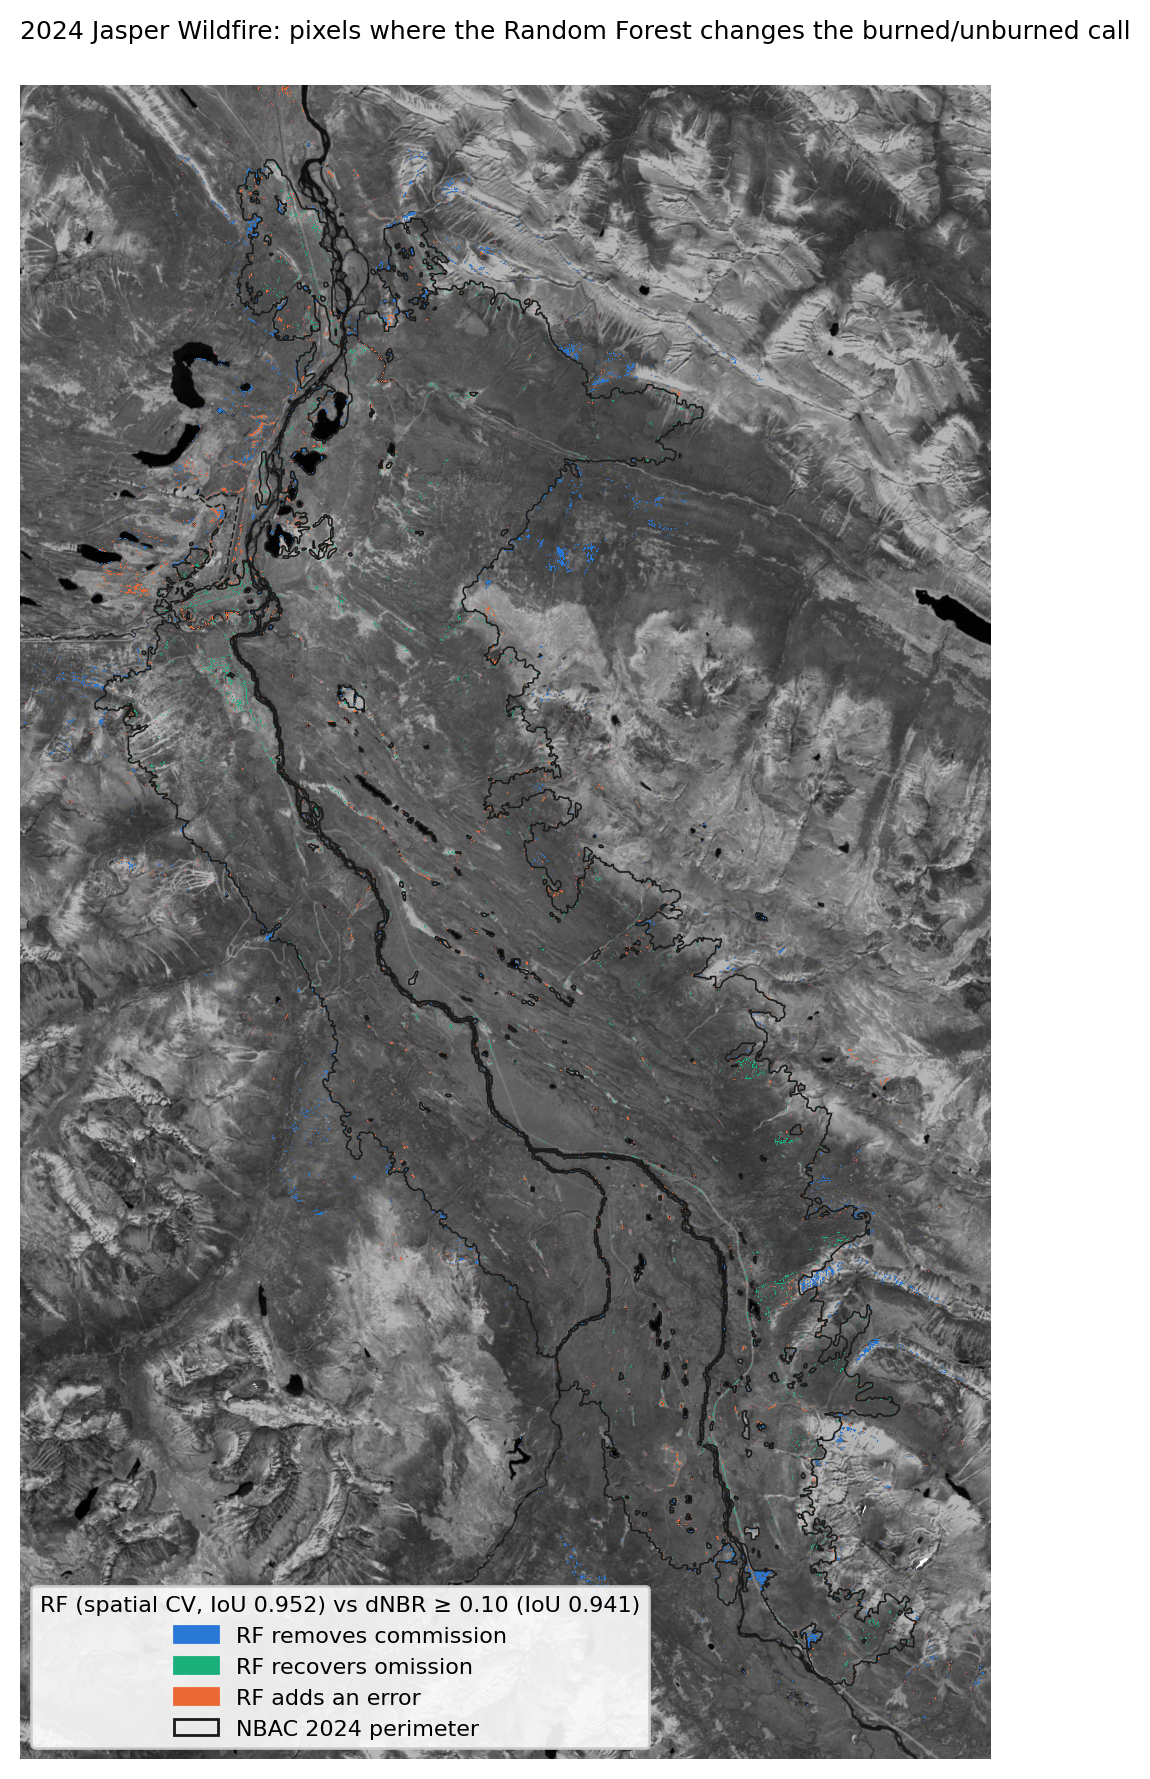

In [6]:
## 4. Where the RF changes the answer vs dNBR >= 0.10
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

thr = X[:, DN] >= BURN_T
CHG = {"RF removes commission": "#2a78d6", "RF recovers omission": "#1baf7a", "RF adds an error": "#eb6834"}
flat = np.full(shape[0] * shape[1], np.nan, "float32")
flat[idx[thr & ~oof_rf & ~y]] = 0
flat[idx[~thr & oof_rf & y]] = 1
flat[idx[(thr != oof_rf) & (oof_rf != y)]] = 2
chg = flat.reshape(shape)
for i, k in enumerate(CHG):
    print(f"{k}: {(chg == i).sum() * PIX_HA:,.1f} ha")

xs, ys = d.x.values, d.y.values
ext = [xs.min() - 10, xs.max() + 10, ys.min() - 10, ys.max() + 10]
base = (pre["B8A"] / pre["B8A"].quantile(0.98)).clip(0, 1)
fig, ax = plt.subplots(figsize=(8, 9), dpi=200)
ax.imshow(base, cmap="gray", vmin=0, vmax=1.4, extent=ext)
ax.imshow(chg, cmap=ListedColormap(list(CHG.values())), vmin=-0.5, vmax=2.5, extent=ext, interpolation="nearest")
perim.boundary.plot(ax=ax, color="#1a1a19", lw=0.6)
town.boundary.plot(ax=ax, color="#1a1a19", lw=0.6, linestyle="--")
ax.legend(handles=[Patch(color=c, label=l) for l, c in CHG.items()]
          + [Patch(facecolor="none", edgecolor="#1a1a19", label="NBAC 2024 perimeter")],
          loc="lower left", fontsize=8, framealpha=0.9,
          title=f"RF (spatial CV, IoU {cv.IoU.iloc[2]:.3f}) vs dNBR ≥ 0.10 (IoU {cv.IoU.iloc[0]:.3f})", title_fontsize=8)
ax.set_title("2024 Jasper Wildfire: pixels where the Random Forest changes the burned/unburned call", fontsize=9, loc="left")
ax.set_axis_off(); plt.tight_layout()
plt.savefig(FIG / "rf_changes.png", bbox_inches="tight")

In [7]:
## 5. Save
cv.round(4).to_csv(FIG / "rf_cv_metrics.csv")
folds.round(4).to_csv(FIG / "rf_cv_folds.csv", index=False)
imp.round(4).to_csv(FIG / "rf_feature_importance.csv", index=False)
print("saved")

saved
